# Isospectral drums: can one hear the shape of a drum?

Mark Kac asked in 1966 whether the tones of a drum, the eigenfrequencies of its membrane, determine its shape. In 1992
Gordon, Webb and Wolpert answered no: two different drums, each made of seven half-squares, have exactly the same
eigenvalues. The example is their pair of drums as planex2d faces: netgen meshes them, NGSolve computes their
spectra, and the spectra agree. What can be heard is the area and the perimeter, which the two drums share.

![The first modes of two different drums that sound the same](../_static/gallery/isospectral-drums.png){.result}

In [1]:
import math
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation
import ngsolve as ngs
from ngsolve import solvers
import planex as px

In [2]:
from docs_figures import Row

## The drums

The two drums are eight-sided polygons, and each covers seven right isosceles triangles with legs of 2 (Figure 1).

In [3]:
drums = {
    "first": [(-3, -3), (-3, -1), (1, 3), (1, 1), (3, 1), (1, -1), (-1, -1), (-1, -3)],
    "second": [(-3, 1), (1, 1), (1, 3), (3, 1), (1, -1), (-1, -1), (-1, -3), (-3, -1)],
}
faces = {name: px.FromPolyline(points, closed=True).Face() for name, points in drums.items()}

In [4]:
Row((faces["first"], "The first drum"), (faces["second"], "The second drum"),
    caption="The drums of Gordon, Webb and Wolpert")

**Check:** both have the area of seven halves of a 2 × 2 square, 14, and the same perimeter:

In [5]:
for name, face in faces.items():
    print(name, "area", face.mass, "perimeter", face.outer.mass)

first area 14.0 perimeter 20.48528137423857
second area 14.0 perimeter 20.485281374238568


## The tones

The membrane's eigenvalues satisfy −Δu = λu inside and u = 0 on the rim. NGSolve's preconditioned inverse iteration
(PINVIT) finds the lowest twelve, and with the matrix's own inverse as the preconditioner, it is plain inverse
iteration on a block of vectors. The computation runs on a coarse and a finer mesh. On the finer one, the largest
relative difference between the two drums drops by almost an order of magnitude, while each eigenvalue itself
settles. The remaining difference is discretization error, because the two drums are meshed differently, so a single
eigenvalue can also move the other way.

In [6]:
def spectrum(face, maxh, order, count=12):
    mesh = ngs.Mesh(px.OCCGeometry(face).GenerateMesh(maxh=maxh))
    fes = ngs.H1(mesh, order=order, dirichlet=".*")
    u, v = fes.TnT()
    a = ngs.BilinearForm(ngs.grad(u) * ngs.grad(v) * ngs.dx).Assemble()
    m = ngs.BilinearForm(u * v * ngs.dx).Assemble()
    pre = a.mat.Inverse(fes.FreeDofs(), inverse="sparsecholesky")
    values, vectors = solvers.PINVIT(a.mat, m.mat, pre, num=count, maxit=30, printrates=False)
    modes = []
    for vector in vectors:
        mode = ngs.GridFunction(fes)
        mode.vec.data = vector
        modes.append(mode)
    return list(values), mesh, modes

The coarse mesh has elements of 0.5 and order 3, the finer one elements of 0.25 and order 4:

In [7]:
results = {}
for maxh, order in ((0.5, 3), (0.25, 4)):
    results[maxh] = {name: spectrum(face, maxh, order) for name, face in faces.items()}
    first, second = results[maxh]["first"][0], results[maxh]["second"][0]
    print("maxh", maxh, "order", order)
    for n, (x, y) in enumerate(zip(first, second)):
        print(" ", n + 1, round(x, 8), round(y, 8), "relative difference", f"{abs(x - y) / x:.1e}")

maxh 0.5 order 3
  1 2.54254991 2.54376913 relative difference 4.8e-04
  2 3.66042537 3.66047702 relative difference 1.4e-05
  3 5.1850343 5.18480432 relative difference 4.4e-05
  4 6.54010001 6.53998996 relative difference 1.7e-05
  5 7.25680242 7.25849344 relative difference 2.3e-04
  6 9.21405801 9.21459753 relative difference 5.9e-05
  7 10.60436723 10.6047418 relative difference 3.5e-05
  8 11.54537597 11.54492084 relative difference 3.9e-05
  9 12.3394631 12.33866449 relative difference 6.5e-05
  10 13.06947494 13.07076493 relative difference 9.9e-05
  11 14.3217462 14.32165493 relative difference 6.4e-06
  12 15.89767294 15.8957854 relative difference 1.2e-04


maxh 0.25 order 4
  1 2.5388135 2.53883184 relative difference 7.2e-06
  2 3.65639254 3.65649947 relative difference 2.9e-05
  3 5.17727974 5.17756992 relative difference 5.6e-05
  4 6.5379232 6.53796685 relative difference 6.7e-06
  5 7.24969402 7.24970424 relative difference 1.4e-06
  6 9.21004374 9.21007631 relative difference 3.5e-06
  7 10.59801399 10.59803454 relative difference 1.9e-06
  8 11.54168794 11.54173174 relative difference 3.8e-06
  9 12.33700558 12.33700558 relative difference 2.1e-10
  10 13.05620709 13.05635292 relative difference 1.1e-05
  11 14.31471725 14.31486052 relative difference 1.0e-05
  12 15.9186829 15.87556683 relative difference 2.7e-03


## Same tone, different shape

The figure shows the first four modes of each drum. The eigenvalues match, but the shapes of the vibration do
not.

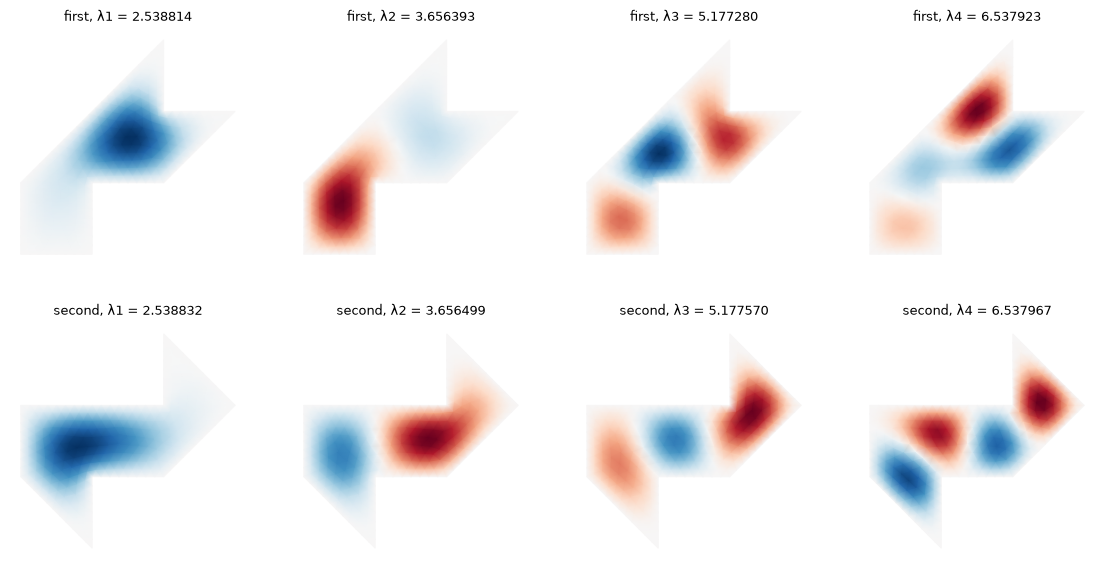

In [8]:
def picture(ax, mesh, mode):
    xy = [v.point for v in mesh.vertices]
    triangles = [[v.nr for v in el.vertices] for el in mesh.Elements(ngs.VOL)]
    values = mode.vec.FV().NumPy()[:mesh.nv]
    scale = max(abs(values.min()), abs(values.max()))
    grid = Triangulation([p[0] for p in xy], [p[1] for p in xy], triangles)
    ax.tripcolor(grid, values / scale, shading="gouraud", cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_aspect("equal")
    ax.axis("off")


fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, name in zip(axes, faces):
    values, mesh, modes = results[0.25][name]
    for n, ax in enumerate(row):
        picture(ax, mesh, modes[n])
        ax.set_title(f"{name}, λ{n + 1} = {values[n]:.6f}", fontsize=9)
plt.show()

In [9]:
import sys
sys.path.insert(0, "..")
from gallery import save_scene, save_figure, save_animation, HIDDEN
card, pair = plt.subplots(1, 2, figsize=(10, 5))
for ax, name in zip(pair, faces):
    values, mesh, modes = results[0.25][name]
    picture(ax, mesh, modes[0])
    faces[name].outer.Plot(ax=ax, legend=False)
save_figure(card, "isospectral-drums", bare=True)